In [3]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17) 
  
# data (as pandas dataframes) 
X = breast_cancer_wisconsin_diagnostic.data.features 
y = breast_cancer_wisconsin_diagnostic.data.targets 

In [7]:
df = pd.concat([X, y], axis=1)
df.columns[:-1]

Index(['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1',
       'compactness1', 'concavity1', 'concave_points1', 'symmetry1',
       'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2',
       'smoothness2', 'compactness2', 'concavity2', 'concave_points2',
       'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3',
       'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3',
       'symmetry3', 'fractal_dimension3'],
      dtype='object')

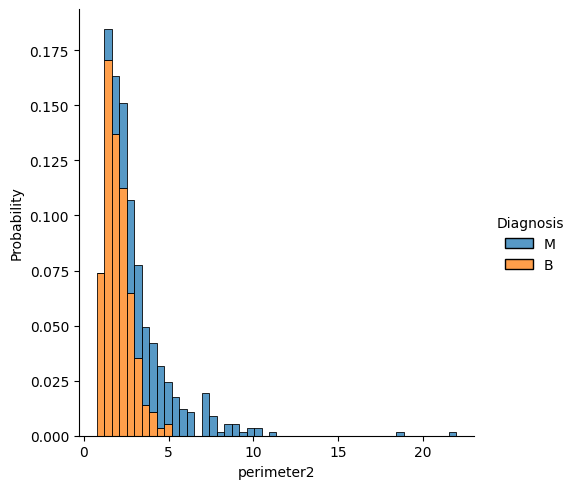

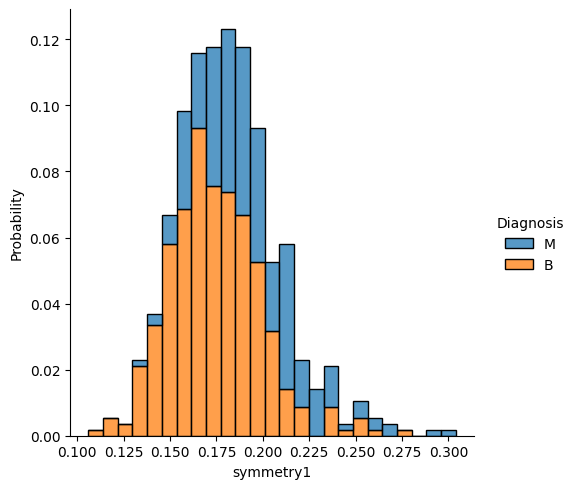

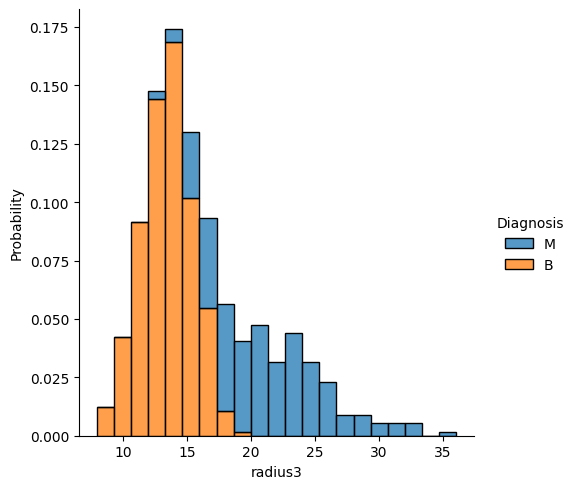

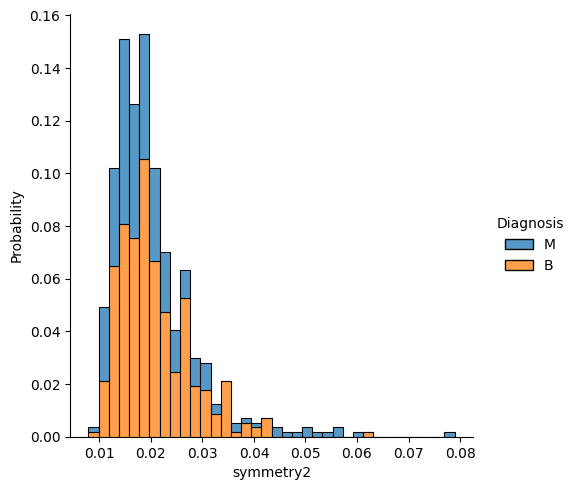

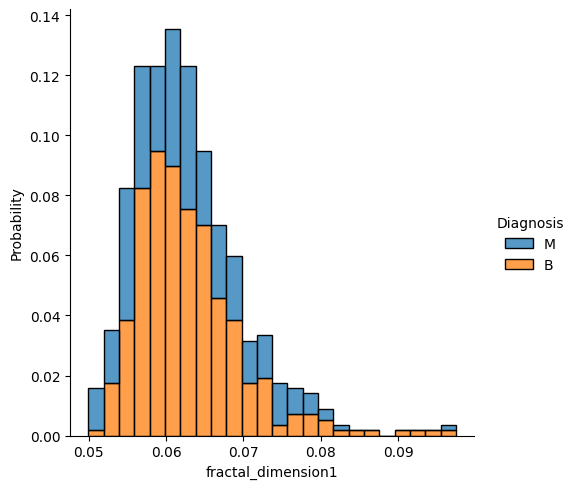

In [11]:
cols = np.random.choice(df.columns[5:-1], size=5, replace=False)
for col in cols:
    sns.displot(data=df,x=col,hue="Diagnosis",stat="probability",multiple="stack")

In [12]:
cat_col = ['Diagnosis']

df_enc = pd.get_dummies(df,columns=cat_col,dtype=int)
df_enc.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis_B,Diagnosis_M
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,1


In [13]:
df_2 = df_enc.drop(columns=['Diagnosis_B'],axis=1)
df_2.head(1)

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis_M
0,17.99,10.38,122.8,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,1


In [14]:
X = df_2.copy().drop(columns=['Diagnosis_M'],axis=1)
y = df_2['Diagnosis_M']

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.1,
    random_state=42,
    stratify=y
)

continuous_cols = X.columns

mean = X_train[continuous_cols].mean()
std = X_train[continuous_cols].std()

X_train[continuous_cols] = (
    X_train[continuous_cols] - mean
) / std

X_val[continuous_cols] = (
    X_val[continuous_cols] - mean
) / std

In [17]:
class LayerDense:
    def __init__(self,inputs,neurons):
        self.weights = np.random.randn(inputs,neurons) + np.sqrt(1/inputs)
        self.biases = np.zeros((1,neurons))
    def forward(self,X):
        self.output = np.dot(X,self.weights) + self.biases
        return self.output
    
def Relu(z):
    return np.maximum(0,z)

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1/(1+np.exp(-z))

def loss_func(y_pred,y):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1-epsilon)
    loss = -np.mean(y*np.log(y_pred)+(1-y)*np.log(1-y_pred))
    return loss

In [20]:
layer_1 = LayerDense(len(X.columns),64)
layer_2 = LayerDense(64,32)
layer_3 = LayerDense(32,1)

In [21]:
def update_parameters(dw1,db1,dw2,db2,dw3,db3,lr):
    
    layer_1.weights -= lr * dw1
    layer_1.biases -= lr * db1
    layer_2.weights -= lr * dw2
    layer_2.biases -= lr * db2
    layer_3.weights -= lr * dw3
    layer_3.biases -= lr * db3

In [25]:
y_train = y_train.reshape(-1, 1)

In [26]:
X_train = np.asarray(X_train, dtype=np.float64)
y_train = np.asarray(y_train, dtype=np.float64)

In [27]:
best_loss = float('inf')

best_W1 = None
best_b1 = None
best_W2 = None
best_b2 = None
best_W3 = None
best_b3 = None

In [28]:
learning_rate = 0.25
epochs = 500
batch_size = 256

loss_history = []

for epoch in range(1, epochs + 1):

    indices = np.random.permutation(X_train.shape[0])

    X_shuffled = X_train[indices]
    y_shuffled = y_train[indices]

    epoch_loss = 0

    for start in range(0, X_train.shape[0], batch_size):

        end = start + batch_size

        X_batch = X_shuffled[start:end]
        y_batch = y_shuffled[start:end]

        m = X_batch.shape[0]

        z1 = layer_1.forward(X_batch)
        a1 = Relu(z1)

        z2 = layer_2.forward(a1)
        a2 = Relu(z2)

        z3 = layer_3.forward(a2)
        a3 = sigmoid(z3)

        loss = loss_func(a3, y_batch)

        epoch_loss += loss * m

        dz3 = a3 - y_batch

        dw3 = np.dot(a2.T, dz3) / m
        db3 = np.sum(dz3, axis=0, keepdims=True) / m

        da2 = np.dot(dz3, layer_3.weights.T)
        dz2 = da2 * (z2 > 0)

        dw2 = np.dot(a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        da1 = np.dot(dz2, layer_2.weights.T)
        dz1 = da1 * (z1 > 0)

        dw1 = np.dot(X_batch.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        update_parameters(
            dw1, db1,
            dw2, db2,
            dw3, db3,
            learning_rate
        )

    epoch_loss /= X_train.shape[0]
    loss_history.append(epoch_loss)

    if epoch_loss < best_loss:

        best_loss = epoch_loss

        best_W1 = layer_1.weights.copy()
        best_b1 = layer_1.biases.copy()

        best_W2 = layer_2.weights.copy()
        best_b2 = layer_2.biases.copy()

        best_W3 = layer_3.weights.copy()
        best_b3 = layer_3.biases.copy()

    if epoch % 50 == 0:
        print(f"Epoch: {epoch} | Loss: {epoch_loss:.6f}")

Epoch: 50 | Loss: 0.009400
Epoch: 100 | Loss: 0.004876
Epoch: 150 | Loss: 0.004211
Epoch: 200 | Loss: 0.003873
Epoch: 250 | Loss: 0.003635
Epoch: 300 | Loss: 0.003434
Epoch: 350 | Loss: 0.003300
Epoch: 400 | Loss: 0.002322
Epoch: 450 | Loss: 0.001526
Epoch: 500 | Loss: 0.001189


In [29]:
layer_1.weights = best_W1.copy()
layer_1.biases = best_b1.copy()

layer_2.weights = best_W2.copy()
layer_2.biases = best_b2.copy()

layer_3.weights = best_W3.copy()
layer_3.biases = best_b3.copy()

In [31]:
y_val = np.asarray(y_val).reshape(-1, 1)

In [34]:
z1 = layer_1.forward(X_val)
a1 = Relu(z1)
z2 = layer_2.forward(a1)
a2 = Relu(z2)
z3 = layer_3.forward(a2)
a3 = sigmoid(z3)

y_pred = (a3 >= 0.5).astype(int)
accuracy = np.mean(y_pred == y_val) * 100
print("Validation Accuracy:", accuracy)

Validation Accuracy: 98.24561403508771


In [35]:
from sklearn.metrics import confusion_matrix, classification_report
y_pred = (a3 >= 0.5).astype(int)
print(confusion_matrix(y_val, y_pred))
print(classification_report(y_val, y_pred))

[[36  0]
 [ 1 20]]
              precision    recall  f1-score   support

           0       0.97      1.00      0.99        36
           1       1.00      0.95      0.98        21

    accuracy                           0.98        57
   macro avg       0.99      0.98      0.98        57
weighted avg       0.98      0.98      0.98        57



In [36]:
np.savez(
    "nn_model.npz",
    w1=best_W1,
    b1=best_b1,
    w2=best_W2,
    b2=best_b2,
    w3=best_W3,
    b3=best_b3,
    mean=mean.values,
    std=std.values
)
print("Model Saved !")

Model Saved !
